<a href="https://colab.research.google.com/github/QuirozAlaniz/Remuestreoarbol/blob/main/Actividad_Calificada_Particion_Remuestreo_Arbol_269723.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad Calificada: Partición y Remuestreo con Árbol de Decisión

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**


**Nombre: Francisco Daniel Quiroz Alaniz**

**Matricula: 269723**

**Ficha técnica**

| | |
|---|---|
| **Modalidad** | Individual |
| **Entorno** | Google Colab |
| **Dataset** | Titanic (pasajeros del RMS Titanic, clasificación binaria) |
| **Modelo** | Árbol de Decisión (`DecisionTreeClassifier`) |
| **Puntaje total** | 100 puntos |
| **Fecha de entrega** | 26 de octubre de 2026 |

**Objetivo**

Aplicar partición hold-out estratificada y dos esquemas de validación cruzada (`StratifiedKFold` y `RepeatedStratifiedKFold`) para estimar el desempeño de un Árbol de Decisión, y justificar, con base en el sesgo y la varianza de la estimación, qué método reportarías como resultado final.

**Dataset**

El dataset contiene 891 pasajeros del Titanic, con la variable `survived` (0 = no sobrevivió, 1 = sobrevivió) como variable objetivo. Tiene valores ausentes genuinos en `age` (177 casos) y `embarked` (2 casos) — no son valores agregados artificialmente para esta actividad.

**Instrucciones generales**

- Completa únicamente las celdas marcadas con `# TODO`. No modifiques las celdas de preparación de datos ni los hiperparámetros ya indicados (`max_depth=4`, `random_state=0`), para que tus resultados sean comparables con los de tus compañeros.
- Cada actividad tiene una parte de código y una pregunta de interpretación en una celda de texto (Markdown). Responde directamente debajo de **Tu respuesta:**.
- No se califican fragmentos de código comentados o dejados sin completar (`# TODO` sin resolver).
- Antes de entregar, ejecuta todo el notebook de principio a fin (`Entorno de ejecución > Reiniciar y ejecutar todo` en Colab) y verifica que no queden errores.

**Entrega**

Sube a Moodle un archivo `.txt` con el enlace a tu notebook de Colab o GitHub (con permisos de lectura habilitados). La subida del archivo `.ipynb` es opcional, pero recomendada como respaldo.


## Preparación de los datos

Esta sección se proporciona completa: no es parte de la evaluación. Carga el dataset, selecciona las variables predictoras y aplica un tratamiento mínimo a los valores ausentes y a las variables categóricas, para que puedas concentrarte en la partición y el remuestreo.


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)

print(f"Observaciones: {df.shape[0]}, columnas: {df.shape[1]}")
print("Valores ausentes por columna (solo las que tienen alguno):")
print(df.isna().sum()[df.isna().sum() > 0])

# Variables predictoras: se dejan fuera las que son redundantes con 'survived'
# (alive, who, adult_male), las de muy alta cardinalidad (deck, con 688 ausentes)
# o duplicadas en otra forma (class es la versión en texto de pclass).
variables = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = df[variables].copy()
y = df["survived"].copy()

# Tratamiento mínimo, dado: imputar age con la mediana y embarked con la moda,
# y codificar las dos variables categóricas como enteros.
X["age"] = X["age"].fillna(X["age"].median())
X["embarked"] = X["embarked"].fillna(X["embarked"].mode()[0])
X["sex"] = X["sex"].map({"male": 0, "female": 1})
X["embarked"] = X["embarked"].map({"S": 0, "C": 1, "Q": 2})

print(f"\nVariables predictoras: {list(X.columns)}")
print(f"Distribución de la variable objetivo (survived): {dict(y.value_counts().sort_index())}")


Observaciones: 891, columnas: 15
Valores ausentes por columna (solo las que tienen alguno):
age            177
embarked         2
deck           688
embark_town      2
dtype: int64

Variables predictoras: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
Distribución de la variable objetivo (survived): {0: np.int64(549), 1: np.int64(342)}


---
## Actividad 1 — Hold-out estratificado (20 pts)

**1.1 (15 pts).** Completa la partición hold-out: reserva el 20% de las observaciones para prueba, con estratificación por `y` y `random_state=42`. Ajusta un `DecisionTreeClassifier` con `max_depth=4` y `random_state=0` usando el conjunto de entrenamiento, y calcula su accuracy sobre el conjunto de prueba.


              precision    recall  f1-score   support

           0       0.82      0.90      0.86       110
           1       0.81      0.68      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.82      0.82      0.81       179

[[99 11]
 [22 47]]


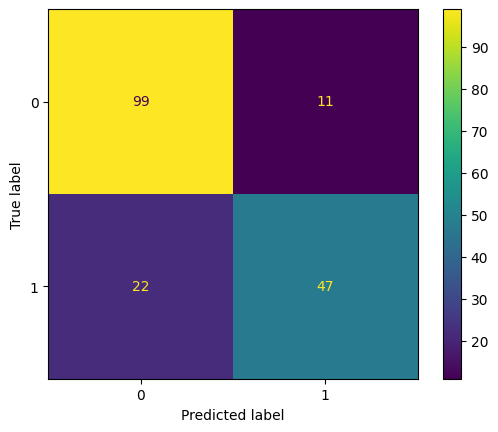

Observaciones de entrenamiento: 712
Observaciones de prueba: 179
Accuracy en Hold-out: 0.816


In [34]:
# TODO 1.1: completa la partición hold-out y el ajuste del modelo.
# Revisa las condiciones indicadas arriba (porcentaje de prueba, estratificación, random_state).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, stratify = y, random_state = 0 )

arbol = DecisionTreeClassifier(criterion = 'gini', max_depth=4, random_state=0)
arbol.fit(X_train, y_train)
# TODO: ajusta 'arbol' con los datos de entrenamiento

acc_holdout = accuracy_score(y_test, arbol.predict(X_test))  # TODO: calcula el accuracy de 'arbol' sobre el conjunto de prueba
y_pred = arbol.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred, labels=arbol.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=arbol.classes_)
disp.plot()
plt.show()


# TODO: imprime el número de observaciones de entrenamiento, el número de observaciones
# de prueba y el accuracy obtenido en prueba (acc_holdout).
print(f"Observaciones de entrenamiento: {len(X_train)}")
print(f"Observaciones de prueba: {len(X_test)}")
print(f"Accuracy en Hold-out: {acc_holdout:.3f}")


**1.2 (5 pts).** El Titanic tiene una proporción de supervivencia desbalanceada (aproximadamente 38% sobrevivió, 62% no). ¿Qué problema evita la estratificación (`stratify=y`) en este caso específico, y qué podría pasar con la partición si no se usara?

**Tu respuesta:**
\
Stratify = y nos garantiza que la proporción de la clasificación en los conjuntos de entrenamiento y prueba se mantiene, un ejemplo muy extremo es que evita que en el conjunto de entrenamiento haya solamente gente que no sobrevivió y que en el conjunto de prueba pura gente que sí sobrevivió.
\
Si eso ocurriera, el modelo no aprendería cómo lucen los que sobrevivieron y el accuracy se desplomaría.

---
## Actividad 2 — StratifiedKFold (25 pts)

**2.1 (15 pts).** Completa la validación cruzada con `StratifiedKFold`: 5 folds, `shuffle=True` y `random_state=42`. Usa `cross_validate` con un `DecisionTreeClassifier(max_depth=4, random_state=0)` nuevo (mismos hiperparámetros que en la Actividad 1) y reporta la media y la desviación estándar (`ddof=1`) del accuracy sobre los 5 folds.


In [35]:
# TODO 2.1: completa la validación cruzada con StratifiedKFold.
# Revisa las condiciones indicadas arriba (número de folds, shuffle, random_state).
cv_kfold = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
    # TODO: agrega aquí los argumentos de StratifiedKFold

arbol_kfold = DecisionTreeClassifier(max_depth=4, random_state=0)
resultados_kfold = cross_validate(arbol_kfold, X, y, cv=cv_kfold, scoring = "accuracy")  # TODO: usa cross_validate con 'arbol_kfold', 'cv_kfold' y la métrica de accuracy


scores_kfold = resultados_kfold["test_score"]  # TODO: extrae el arreglo de accuracy por fold a partir de 'resultados_kfold'

# TODO: imprime el accuracy obtenido en cada fold, su media y su desviación estándar
print(f"  Accuracy por fold:    {np.round(scores_kfold, 3)}")
print(f"  Media:                {scores_kfold.mean():.3f}")
print(f"  Desv. est. (ddof=1):  {scores_kfold.std(ddof=1):.3f}")
# (usa ddof=1 para la desviación estándar, como se vio en la sesión).


  Accuracy por fold:    [0.832 0.826 0.792 0.809 0.837]
  Media:                0.819
  Desv. est. (ddof=1):  0.019


**2.2 (10 pts).** Compara la media del accuracy de `StratifiedKFold` con el accuracy único que obtuviste en la Actividad 1. ¿Por qué un solo valor de hold-out no es suficiente para saber si ese resultado es representativo del desempeño real del modelo?

**Tu respuesta:**
\
Un solo valor de hold-out depende mucho de la partición aleatoria efectuada. Si la partición resulta "fácil" o "difícil", el accuracy puede verse sobreestimado o subestimado dando un dato poco confiable.

---
## Actividad 3 — RepeatedStratifiedKFold (25 pts)

**3.1 (15 pts).** Completa la validación cruzada repetida: 5 folds, 5 repeticiones y `random_state=42`. Usa `cross_validate` con el mismo modelo (`DecisionTreeClassifier(max_depth=4, random_state=0)`) y reporta la media y la desviación estándar (`ddof=1`) sobre las 25 estimaciones resultantes.


In [36]:
# TODO 3.1: completa la validación cruzada repetida.
# Revisa las condiciones indicadas arriba (número de folds, número de repeticiones, random_state).
cv_repetido = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 5, random_state = 42)

arbol_repetido = DecisionTreeClassifier(max_depth=4, random_state=0)
resultados_repetido = cross_validate(arbol_repetido, X, y, cv = cv_repetido, scoring = "accuracy")  # TODO: usa cross_validate con 'arbol_repetido', 'cv_repetido' y la métrica de accuracy

scores_repetido = resultados_repetido["test_score"]
print(f"  Número de estimaciones: {len(scores_repetido)}  (5 folds x 5 repeticiones)")
print(f"  Media:                  {scores_repetido.mean():.3f}")
print(f"  Desv. est. (ddof=1):    {scores_repetido.std(ddof=1):.3f}")

# TODO: imprime el número de estimaciones obtenidas, su media y su desviación estándar (ddof=1).


  Número de estimaciones: 25  (5 folds x 5 repeticiones)
  Media:                  0.809
  Desv. est. (ddof=1):    0.022


**3.2 (10 pts).** Compara la desviación estándar de `RepeatedStratifiedKFold` con la de `StratifiedKFold` (Actividad 2). ¿Qué fuente de variabilidad adicional captura la versión repetida que una sola corrida de `StratifiedKFold` no puede capturar?

**Tu respuesta:**
La desviación estándar de RepeatedStratifiedKFold es de 0.022 mientras que la de StratifiedKfold es de 0.019, esto se debe a que el RepeatedStratiefiedKfold hace 5 repeticiones y en cada una barajea los datos otra vez, por eso capta más variabilidad.

---
## Actividad 4 — Comparación y justificación (15 pts)

**4.1 (10 pts).** Completa la tabla comparativa con los tres resultados obtenidos. Para hold-out, al ser una sola estimación, no hay desviación estándar.


In [37]:
# TODO 4.1: completa la tabla comparativa con los tres métodos.
resumen = pd.DataFrame({
    "método": ["Hold-out", "StratifiedKFold", "RepeatedStratifiedKFold"],
    "n_estimaciones": [1, 5, 25],  # completa: número de estimaciones de cada método
    "media_accuracy": [0.82, 0.819, 0.809],  # completa con los tres valores ya calculados
    "desv_est": [None, 0.019, 0.022],  # completa; np.nan para hold-out
})
resumen


,método,n_estimaciones,media_accuracy,desv_est
0,Hold-out,1,0.820,NaN
1,StratifiedKFold,5,0.819,0.019
2,RepeatedStratifiedKFold,25,0.809,0.022


**4.2 (5 pts).** Si tuvieras que reportar un solo número como el desempeño esperado de este Árbol de Decisión en el dataset del Titanic, ¿cuál de los tres métodos usarías y por qué? Justifica tu respuesta en términos de sesgo y varianza de la estimación, no solo del valor de accuracy obtenido.

**Tu respuesta:**
\
Reportaría una media de accuracy de 80.9% (0.809) con una desviación estándar de 0.022 porque si bien el método "hold.out" da un promedio de 82%, ese dato es sensible a una manera de separar los datos en entrenamiento-prueba, pero al usar el "RepeatedStratifiedKFold" nos encontramos que el promedio de accuracy baja ligeramente, esto se debe a que se realiza la prueba más número de beces teniendo un resultado más confiable.
\
Por eso este método es el que más se acerca a la realidad.

---
## Reflexión final (15 pts)

Responde en 6 a 10 líneas: ¿qué papel juega la elección del método de partición o remuestreo cuando se evalúa un modelo de clasificación, y qué factores del problema (tamaño del dataset, balance de clases, costo de entrenamiento) tomarías en cuenta para elegir uno sobre otro en un caso distinto al de esta actividad?

**Tu respuesta:**
\
La elección del método de partición para evaluar un modelo de clasificación se ve afectado principalmente por la representatividad de los datos, es decir en cada partición de datos prueba-test ambos subconjuntos deben ser representativos del Universo de datos. El resultado del método de evaluación influye en que mientras más pruebas hagamos, mejor idea tendremos de qué tan bien o mal funciona el modelo. Por eso por lo general "RepeatedStratifiedKFold" es más representativo, porque mide el accuracy tomando en cuenta muchas pruebas.
\
Por el contrario el hold-out simple al probar con solo un conjunto el resultado es menos confiable, pues ese conjunto puede no estar bien estratificado y mostrar un accuracy tan real.  

---
## Rúbrica

| Criterio | Excelente | Bueno | Insuficiente | No entregado / Incorrecto | Puntos |
|---|---|---|---|---|---|
| **1.1 Hold-out estratificado** | Partición y ajuste correctos; accuracy calculado e interpretado correctamente. | Partición y ajuste correctos, con un error menor (p. ej. un argumento incompleto) que no afecta el resultado final. | Partición o ajuste con errores que alteran el resultado (p. ej. sin estratificar, sin `random_state`). | Celda sin completar o con errores que impiden su ejecución. | 15 |
| **1.2 Interpretación de la estratificación** | Explica correctamente el riesgo de desbalance en la partición y por qué `stratify` lo evita. | Explica la idea general pero de forma incompleta o imprecisa. | Respuesta genérica, sin relación con el desbalance de clases del dataset. | Sin respuesta. | 5 |
| **2.1 StratifiedKFold** | Configuración correcta de `cv` y `cross_validate`; media y desviación estándar reportadas con `ddof=1`. | Correcto, con un error menor que no cambia el resultado (p. ej. `ddof` por defecto). | Configuración incompleta o métrica mal calculada. | Celda sin completar o con errores que impiden su ejecución. | 15 |
| **2.2 Comparación hold-out vs. k-fold** | Explica con claridad por qué una sola partición no es representativa y cómo k-fold promedia sobre varias particiones. | Identifica la idea central pero sin justificarla completamente. | Comparación superficial, sin referirse a la variabilidad entre particiones. | Sin respuesta. | 10 |
| **3.1 RepeatedStratifiedKFold** | Configuración correcta de `cv` y `cross_validate`; media y desviación estándar reportadas sobre las 25 estimaciones. | Correcto, con un error menor que no cambia el resultado. | Configuración incompleta (p. ej. `n_repeats` incorrecto) o métrica mal calculada. | Celda sin completar o con errores que impiden su ejecución. | 15 |
| **3.2 Fuente de variabilidad adicional** | Identifica correctamente que la repetición varía la configuración de folds entre repeticiones, no solo las observaciones dentro de un fold. | Identifica que hay más variabilidad capturada, sin precisar el mecanismo. | Respuesta genérica o incorrecta sobre qué varía entre repeticiones. | Sin respuesta. | 10 |
| **4.1 Tabla comparativa** | Tabla completa y correcta, con `np.nan` o vacío en la desviación estándar de hold-out. | Tabla completa con un valor incorrecto o mal ubicado. | Tabla incompleta o con varios valores incorrectos. | Celda sin completar. | 10 |
| **4.2 Justificación del método elegido** | Justifica la elección con el argumento de sesgo/varianza de la estimación, no solo con el valor numérico de accuracy. | Justifica la elección, pero basándose solo en qué método dio el accuracy más alto. | Elige un método sin justificación relacionada con sesgo o varianza. | Sin respuesta. | 5 |
| **Reflexión final** | Identifica con claridad los factores relevantes (tamaño del dataset, balance de clases, costo) y los conecta con el método de partición o remuestreo adecuado. | Identifica algunos factores relevantes, de forma parcial. | Reflexión genérica, sin relación específica con los factores de decisión vistos en la sesión. | Sin respuesta. | 15 |

**Nota.** La penalización por entrega tardía es del 5% por día calendario, hasta 7 días, después de lo cual la actividad recibe 0 puntos. Esta penalización se aplica sobre el puntaje ya obtenido con la rúbrica, no como parte de ella.
